# AnomaForge — MVTec AD exploration and teacher–student training

This is the **single integrated Colab notebook**. Stage 1 uses `bottle` for visual exploration; subsequent student training draws normal images from **all 15 MVTec AD categories**. The official test set is reserved for evaluation.

## Stage 1 — Mount Google Drive

Keep the MVTec AD category folders together under `MyDrive/ANOMAFORGE/` or `MyDrive/ANOMAFORGE/mvtec_ad/`. Checkpoints are saved separately in `MyDrive/ANOMAFORGE/checkpoints/`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Locate the dataset

The `bottle` category is used for the exploratory plots. The same dataset root is reused for all-category training; each category has a `train/good/` folder.

In [2]:
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/ANOMAFORGE/mvtec_anomaly_detection')
ALL_CATEGORIES = (
    'bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut',
    'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush',
    'transistor', 'wood', 'zipper'
)

# Support either directly extracted category folders or an mvtec_ad/ subfolder.
possible_roots = [PROJECT_DIR, PROJECT_DIR / 'mvtec_ad', PROJECT_DIR / 'MVTec_AD']
MVTEC_ROOT = next(
    (root for root in possible_roots if (root / 'bottle' / 'train' / 'good').is_dir()),
    None,
)
if MVTEC_ROOT is None:
    raise FileNotFoundError(
        'Could not find bottle/train/good under ' + str(PROJECT_DIR)
        + '. Extract the MVTec AD dataset and adjust possible_roots if needed.'
    )

BOTTLE_DIR = MVTEC_ROOT / 'bottle'
required = ['train/good', 'test/good', 'ground_truth']
missing = [name for name in required if not (BOTTLE_DIR / name).is_dir()]
if missing:
    raise FileNotFoundError(f'Missing bottle directories: {missing}')

available_categories = [
    name for name in ALL_CATEGORIES if (MVTEC_ROOT / name / 'train' / 'good').is_dir()
]
print('MVTec root:', MVTEC_ROOT)
print('Training categories available:', len(available_categories), 'of 15')
print(', '.join(available_categories))

MVTec root: /content/drive/MyDrive/ANOMAFORGE/mvtec_anomaly_detection
Training categories available: 15 of 15
bottle, cable, capsule, carpet, grid, hazelnut, leather, metal_nut, pill, screw, tile, toothbrush, transistor, wood, zipper


### Inspect dataset labels and image counts

Normal images in each category's `train/good/` folder will be used for student training and development. Real defect examples and masks from `test/` and `ground_truth/` remain for later evaluation.

In [3]:
def image_files(folder):
    return sorted(path for path in folder.glob('*.png') if path.is_file())

print('Normal training-image counts by available category:')
for category in available_categories:
    print(f'  {category:13s}: {len(image_files(MVTEC_ROOT / category / "train" / "good"))}')

print('\nBottle test categories:')
for folder in sorted((BOTTLE_DIR / 'test').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s}: {len(image_files(folder))} images')

print('\nBottle ground-truth masks:')
for folder in sorted((BOTTLE_DIR / 'ground_truth').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s}: {len(image_files(folder))} masks')

Normal training-image counts by available category:
  bottle       : 209
  cable        : 224
  capsule      : 219
  carpet       : 280
  grid         : 264
  hazelnut     : 391
  leather      : 245
  metal_nut    : 220
  pill         : 267
  screw        : 320
  tile         : 230
  toothbrush   : 60
  transistor   : 213
  wood         : 247
  zipper       : 240

Bottle test categories:
  broken_large      : 20 images
  broken_small      : 22 images
  contamination     : 21 images
  good              : 20 images

Bottle ground-truth masks:
  broken_large      : 20 masks
  broken_small      : 22 masks
  contamination     : 21 masks


### View one normal bottle, one defective bottle and its matching mask

This is dataset inspection only. The displayed real defective image and mask are **not** used for model training or threshold selection.

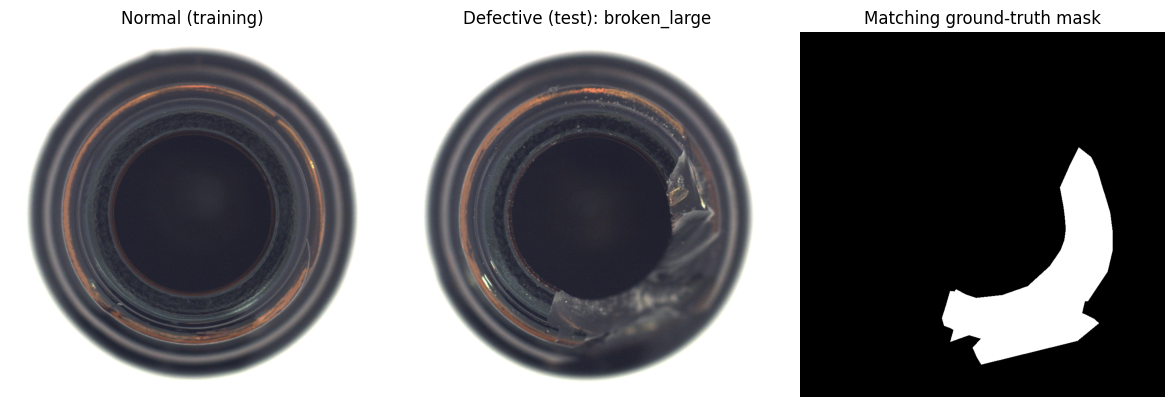

Normal image: 000.png (900, 900)
Defective image: 000.png (900, 900)
Mask: 000_mask.png (900, 900)


In [4]:
from PIL import Image
import matplotlib.pyplot as plt

normal_paths = image_files(BOTTLE_DIR / 'train' / 'good')
assert normal_paths, 'No normal training images were found.'
normal_path = normal_paths[0]

defect_types = [p.name for p in (BOTTLE_DIR / 'test').iterdir()
                if p.is_dir() and p.name != 'good' and image_files(p)]
assert defect_types, 'No defective test images were found.'
defect_type = sorted(defect_types)[0]
defect_path = image_files(BOTTLE_DIR / 'test' / defect_type)[0]
mask_path = BOTTLE_DIR / 'ground_truth' / defect_type / f'{defect_path.stem}_mask.png'
if not mask_path.is_file():
    raise FileNotFoundError(f'Expected matching defect mask was not found: {mask_path}')

normal = Image.open(normal_path).convert('RGB')
defective = Image.open(defect_path).convert('RGB')
mask = Image.open(mask_path).convert('L')

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(normal);    axes[0].set_title('Normal (training)')
axes[1].imshow(defective); axes[1].set_title(f'Defective (test): {defect_type}')
axes[2].imshow(mask, cmap='gray', vmin=0, vmax=255); axes[2].set_title('Matching ground-truth mask')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print('Normal image:', normal_path.name, normal.size)
print('Defective image:', defect_path.name, defective.size)
print('Mask:', mask_path.name, mask.size)

### Check the planned input size

The following simple 224 × 224 tensor check is exploratory. The teacher's own image processor handles final resizing and normalization for training.

In [5]:
import numpy as np
import torch

resized = normal.resize((224, 224), Image.Resampling.BILINEAR)
array = np.asarray(resized, dtype=np.float32) / 255.0
tensor = torch.from_numpy(array).permute(2, 0, 1).contiguous()

print('Prepared input tensor shape:', tuple(tensor.shape))
print('Pixel range:', float(tensor.min()), 'to', float(tensor.max()))
assert tuple(tensor.shape) == (3, 224, 224)
print('Stage 1 tensor check passed.')

Prepared input tensor shape: (3, 224, 224)
Pixel range: 0.12156862765550613 to 1.0
Stage 1 tensor check passed.


---
## Stage 2 — Frozen DINOv3 teacher features

1. Get access to [Meta's DINOv3 ViT-S/16 checkpoint](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m).


We reuse the `normal` PIL image loaded in Stage 1, but run DINOv3's own preprocessing inside `teacher.py`.

In [6]:
%pip install -q "transformers==5.21.0" "huggingface-hub==1.32.0"

In [7]:

# Stage 2B: Load teacher.py from Kshitija's branch

import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ANN-PROJECT-26/ANOMAFORGE.git"

# No slash at the beginning
BRANCH = "feature/kshitija"

# Separate folder for your branch
REPO_DIR = Path("/content/anomaforge_kshitija")


if (REPO_DIR / ".git").is_dir():
    # Check which branch this existing copy is using
    result = subprocess.run(
        ["git", "-C", str(REPO_DIR), "branch", "--show-current"],
        check=True,
        capture_output=True,
        text=True
    )

    current_branch = result.stdout.strip()

    if current_branch != BRANCH:
        raise RuntimeError(
            f"Expected branch '{BRANCH}', but this folder is on "
            f"'{current_branch}'. Check the folder before continuing."
        )

    # Update this branch if a fast-forward update is possible
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", BRANCH],
        check=True
    )

elif REPO_DIR.exists():
    raise RuntimeError(
        f"{REPO_DIR} already exists but is not a Git repository. "
        "Choose a different REPO_DIR."
    )

else:
    # First run: clone your branch
    subprocess.run(
        [
            "git", "clone",
            "--branch", BRANCH,
            "--single-branch",
            REPO_URL,
            str(REPO_DIR)
        ],
        check=True
    )


# Locate teacher.py inside your branch
MODULE_DIR = REPO_DIR / "P1"
TEACHER_FILE = MODULE_DIR / "teacher.py"

if not TEACHER_FILE.is_file():
    raise FileNotFoundError(f"Cannot find: {TEACHER_FILE}")

# Make this folder the first place Python looks for teacher.py
sys.path.insert(0, str(MODULE_DIR))

# Remove any previously imported teacher module from Python's cache
# so this import uses the copy from your branch.
if "teacher" in sys.modules:
    del sys.modules["teacher"]

from teacher import DINOv3Teacher
import teacher as teacher_module

print("GitHub branch:", BRANCH)
print("Teacher loaded from:", teacher_module.__file__)


GitHub branch: feature/kshitija
Teacher loaded from: /content/anomaforge_kshitija/P1/teacher.py


In [8]:

from huggingface_hub import login
import torch

login()
assert "normal" in globals(), "Run Stage 1 first to load the normal PIL image."

teacher = DINOv3Teacher()
teacher_pixels, teacher_features = teacher.extract(normal)

print("Device:", teacher.device)
print("DINOv3 preprocessed pixels:", tuple(teacher_pixels.shape))
print("Teacher spatial features:", tuple(teacher_features.shape))
print("Teacher frozen:", all(not p.requires_grad for p in teacher.model.parameters()))

assert tuple(teacher_pixels.shape) == (1, 3, 224, 224)
assert tuple(teacher_features.shape) == (1, 384, 14, 14)
print("Stage 2 passed: DINOv3 spatial features ready for StudentCNN later.")

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Device: cuda
DINOv3 preprocessed pixels: (1, 3, 224, 224)
Teacher spatial features: (1, 384, 14, 14)
Teacher frozen: True
Stage 2 passed: DINOv3 spatial features ready for StudentCNN later.


---
## Stage 3 — Import and check the Student CNN

The pretrained DINOv3 teacher is frozen. The custom Student CNN is initialized without pretrained weights and must produce the same 384 × 14 × 14 feature shape.

In [9]:
import subprocess
from pathlib import Path
import sys
import importlib
import inspect
import torch


STUDENT_REPO = Path("/content/anomaforge_kshitija")
STUDENT_BRANCH = "feature/kshitija"

if not STUDENT_REPO.exists():
    subprocess.run(
        [
            "git", "clone",
            "--branch", STUDENT_BRANCH,
            "--single-branch",
            "https://github.com/ANN-PROJECT-26/ANOMAFORGE.git",
            str(STUDENT_REPO)
        ],
        check=True
    )

elif not (STUDENT_REPO / ".git").is_dir():
    raise RuntimeError(
        f"{STUDENT_REPO} exists, but it is not a Git repository."
    )

# Verify that the local copy is on your branch
result = subprocess.run(
    ["git", "-C", str(STUDENT_REPO), "branch", "--show-current"],
    check=True,
    capture_output=True,
    text=True
)

current_branch = result.stdout.strip()

if current_branch != STUDENT_BRANCH:
    raise RuntimeError(
        f"Expected {STUDENT_BRANCH}, but found {current_branch}."
    )

print("Student repository:", STUDENT_REPO)
print("Current branch:", current_branch)
print(
    "student.py exists:",
    (STUDENT_REPO / "P2" / "student.py").exists()
)


STUDENT_DIR = STUDENT_REPO / "P2"
STUDENT_FILE = STUDENT_DIR / "student.py"

if not STUDENT_FILE.is_file():
    raise FileNotFoundError(f"Cannot find: {STUDENT_FILE}")

if "teacher" not in globals() or "normal" not in globals():
    raise RuntimeError(
        "First run the notebook cells that create 'normal' and 'teacher'."
    )

# Tell Python where to find student.py
sys.path.insert(0, str(STUDENT_DIR))
importlib.invalidate_caches()

# If student.py was imported before, load the current copy again
if "student" in sys.modules:
    del sys.modules["student"]

from student import StudentCNN
print("Student class loaded from:", inspect.getfile(StudentCNN))

# Reproducible initial student weights (training may later load a checkpoint).
torch.manual_seed(42)
student_model = StudentCNN().to(teacher.device)
student_model.eval()

# Teacher preprocesses the image and produces its features
teacher_pixels, teacher_features = teacher.extract(normal)

# Pass the same preprocessed image to the student
with torch.no_grad():
    student_features = student_model(teacher_pixels)

print("Teacher Device:", teacher.device)
print("Teacher input:   ", tuple(teacher_pixels.shape))
print("Teacher features:", tuple(teacher_features.shape))
print("Student features:", tuple(student_features.shape))

assert teacher_features.shape == student_features.shape
print("Teacher and student feature shapes match.")

print("Student device:", teacher.device)
print(
    "Trainable student parameters:",
    sum(p.numel() for p in student_model.parameters() if p.requires_grad)
)

Student repository: /content/anomaforge_kshitija
Current branch: feature/kshitija
student.py exists: True
Student class loaded from: /content/anomaforge_kshitija/P2/student.py
Teacher Device: cuda
Teacher input:    (1, 3, 224, 224)
Teacher features: (1, 384, 14, 14)
Student features: (1, 384, 14, 14)
Teacher and student feature shapes match.
Student device: cuda
Trainable student parameters: 1273536


---
## Stage 4 — Split normal training images across all categories

Each category is divided into **80% training and 20% development images** using seed 42. All category folders must be present for the shared all-category student. No official MVTec test image is included in either partition.

In [10]:
import random
import torch
import torch.nn.functional as F
from PIL import Image

SPLIT_SEED = 42
missing_categories = sorted(set(ALL_CATEGORIES) - set(available_categories))
if missing_categories:
    raise FileNotFoundError(
        'All-category training requires all 15 MVTec AD categories. '
        'Missing: ' + ', '.join(missing_categories)
        + '. Place each category beside bottle/ under the MVTec root.'
    )

category_train_paths, category_dev_paths = {}, {}
train_paths, dev_paths = [], []

for category in ALL_CATEGORIES:
    originals = image_files(MVTEC_ROOT / category / 'train' / 'good')
    if len(originals) < 2:
        raise ValueError(f'{category}: at least two normal images are needed.')
    shuffled = originals.copy()
    random.Random(SPLIT_SEED).shuffle(shuffled)
    dev_count = max(1, round(len(originals) * 0.20))
    category_train_paths[category] = shuffled[dev_count:]
    category_dev_paths[category] = shuffled[:dev_count]
    train_paths.extend(category_train_paths[category])
    dev_paths.extend(category_dev_paths[category])
    print(f'{category:13s}: {len(category_train_paths[category]):3d} train | '
          f'{len(category_dev_paths[category]):3d} dev')

assert set(train_paths).isdisjoint(dev_paths)
print(f'\nAll categories: {len(train_paths)} training / {len(dev_paths)} development images')
print('Official test images used in training: 0')

teacher.model.eval()
assert all(not p.requires_grad for p in teacher.model.parameters())
print('Teacher frozen:', True)

bottle       : 167 train |  42 dev
cable        : 179 train |  45 dev
capsule      : 175 train |  44 dev
carpet       : 224 train |  56 dev
grid         : 211 train |  53 dev
hazelnut     : 313 train |  78 dev
leather      : 196 train |  49 dev
metal_nut    : 176 train |  44 dev
pill         : 214 train |  53 dev
screw        : 256 train |  64 dev
tile         : 184 train |  46 dev
toothbrush   :  48 train |  12 dev
transistor   : 170 train |  43 dev
wood         : 198 train |  49 dev
zipper       : 192 train |  48 dev

All categories: 2903 training / 726 development images
Official test images used in training: 0
Teacher frozen: True


---
## Stage 5 — Verify that student gradients work

This checks one backward pass on a **temporary** student. The main student is not updated here, so the full training starts from clean initial weights or a saved checkpoint.

In [11]:
# Use a disposable student for this one-step gradient sanity check.
torch.manual_seed(SPLIT_SEED)
probe_student = StudentCNN().to(teacher.device)
probe_optimizer = torch.optim.Adam(probe_student.parameters(), lr=1e-3)
probe_student.train()

with Image.open(train_paths[0]) as image:
    teacher_pixels, teacher_features = teacher.extract(image.convert('RGB'))

probe_optimizer.zero_grad(set_to_none=True)
probe_features = probe_student(teacher_pixels)
assert probe_features.shape == teacher_features.shape

probe_loss = F.mse_loss(
    F.normalize(probe_features, p=2, dim=1),
    F.normalize(teacher_features, p=2, dim=1)
)
first_parameter = next(probe_student.parameters())
weights_before = first_parameter.detach().clone()
probe_loss.backward()
gradient_norm = first_parameter.grad.norm().item()
probe_optimizer.step()
weight_change = (first_parameter.detach() - weights_before).abs().max().item()

print('Teacher / student features:', tuple(teacher_features.shape))
print('One-step loss:', probe_loss.item())
print('Gradient norm:', gradient_norm)
print('Largest sample weight update:', weight_change)
assert gradient_norm > 0 and weight_change > 0

del probe_student, probe_optimizer, probe_features, probe_loss

Teacher / student features: (1, 384, 14, 14)
One-step loss: 0.005077994428575039
Gradient norm: 0.0006973371491767466
Largest sample weight update: 0.0009998530149459839


---
## Stage 6 — Train the student, or restore saved weights

The main Student CNN is trained on normal images across all 15 categories; only the student receives optimizer updates. The next checkpoint cell restores a completed run when available, or resumes the last saved epoch. Change `EPOCHS` to extend training. If no compatible checkpoint exists, training starts from scratch.

In [12]:
# Saved student weights and training-state management (Google Drive).
import hashlib
import inspect
import json

BATCH_SIZE = 4
EPOCHS = 10
LEARNING_RATE = 1e-3
FORCE_RETRAIN = False
REQUIRE_GPU_FOR_TRAINING = True

# A stable experiment ID prevents a bottle-only or older student checkpoint
# from silently being reused for this 15-category configuration.
def relative_image_id(path):
    return Path(path).relative_to(MVTEC_ROOT).as_posix()

run_config = {
    'categories': list(ALL_CATEGORIES),
    'train_ids': sorted(relative_image_id(p) for p in train_paths),
    'dev_ids': sorted(relative_image_id(p) for p in dev_paths),
    'split_seed': SPLIT_SEED,
    'teacher_model': 'facebook/dinov3-vits16-pretrain-lvd1689m',
    'teacher_code_sha256': hashlib.sha256(Path(inspect.getfile(DINOv3Teacher)).read_bytes()).hexdigest(),
    'student_code_sha256': hashlib.sha256(Path(inspect.getfile(StudentCNN)).read_bytes()).hexdigest(),
    'input_size': 224,
    'loss': 'MSE of L2-normalized patch feature maps',
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'checkpoint_schema': 1,
}
run_id = hashlib.sha256(json.dumps(run_config, sort_keys=True).encode()).hexdigest()[:12]

checkpoint_dir = PROJECT_DIR / 'checkpoints'
checkpoint_dir.mkdir(parents=True, exist_ok=True)
best_path = checkpoint_dir / f'student_all_15_{run_id}_best.pt'
last_path = checkpoint_dir / f'student_all_15_{run_id}_last.pt'

# Fresh student/optimizer on every notebook run; load saved state if compatible.
torch.manual_seed(SPLIT_SEED)
student_model = StudentCNN().to(teacher.device)
optimizer = torch.optim.Adam(student_model.parameters(), lr=LEARNING_RATE)
train_history, dev_history = [], []
completed_epochs, best_epoch = 0, 0
best_dev_loss = float('inf')

if not FORCE_RETRAIN:
    restore_from = last_path if last_path.is_file() else best_path
    if restore_from.is_file():
        state = torch.load(restore_from, map_location=teacher.device, weights_only=True)
        if state.get('run_config') != run_config:
            raise RuntimeError('Stored checkpoint does not match this experiment.')
        student_model.load_state_dict(state['model_state_dict'])
        if state.get('optimizer_state_dict') is not None:
            optimizer.load_state_dict(state['optimizer_state_dict'])
        completed_epochs = int(state['epoch'])
        best_epoch = int(state['best_epoch'])
        best_dev_loss = float(state['best_dev_loss'])
        train_history = list(state['train_history'])
        dev_history = list(state['dev_history'])
        print(f'Restored {restore_from.name} (epoch {completed_epochs}).')
    else:
        print('No matching checkpoint. Training will start from scratch.')
else:
    print('FORCE_RETRAIN=True: starting a fresh training run.')

print('Checkpoints:', checkpoint_dir)
print(f'Epochs completed: {completed_epochs}; target: {EPOCHS}')
if completed_epochs >= EPOCHS:
    print('Training is already complete; the next cell will skip it.')

Restored student_all_15_4024b075de93_last.pt (epoch 10).
Checkpoints: /content/drive/MyDrive/ANOMAFORGE/mvtec_anomaly_detection/checkpoints
Epochs completed: 10; target: 10
Training is already complete; the next cell will skip it.


In [13]:
from torch.utils.data import DataLoader


def load_images(paths):
    """Load a batch of normal images as independent RGB PIL objects."""
    with_images = []
    for path in paths:
        with Image.open(path) as image:
            with_images.append(image.convert('RGB'))
    return with_images


def feature_matching_loss(student_features, teacher_features):
    if student_features.shape != teacher_features.shape:
        raise ValueError('Student/teacher feature shapes differ.')
    return F.mse_loss(
        F.normalize(student_features, p=2, dim=1),
        F.normalize(teacher_features, p=2, dim=1)
    )


def run_epoch(paths, training, epoch):
    student_model.train(training)
    loader = DataLoader(
        [str(path) for path in paths],
        batch_size=BATCH_SIZE,
        shuffle=training,
        generator=torch.Generator().manual_seed(SPLIT_SEED + epoch),
        num_workers=0,
    )
    loss_sum, image_count = 0.0, 0
    for batch_paths in loader:
        images = load_images(batch_paths)
        pixels, teacher_features = teacher.extract(images)  # Frozen teacher
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            student_features = student_model(pixels)
            loss = feature_matching_loss(student_features, teacher_features)
            if not torch.isfinite(loss).item():
                raise RuntimeError('Non-finite feature-matching loss.')
            if training:
                loss.backward()
                optimizer.step()
        loss_sum += loss.item() * len(images)
        image_count += len(images)
    return loss_sum / image_count


def save_training_state(path, epoch):
    """Save weights and optimizer/history after each epoch on persistent Drive."""
    state = {
        'model_state_dict': student_model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'epoch': epoch,
        'best_epoch': best_epoch,
        'best_dev_loss': best_dev_loss,
        'train_history': train_history,
        'dev_history': dev_history,
        'run_config': run_config,
    }
    temporary = path.with_name(path.name + '.tmp')
    torch.save(state, temporary)
    temporary.replace(path)


if completed_epochs < EPOCHS and REQUIRE_GPU_FOR_TRAINING and teacher.device.type != 'cuda':
    raise RuntimeError('Select a GPU runtime in Colab before training all 15 categories.')

if completed_epochs >= EPOCHS:
    print(f'Skipping student training: {completed_epochs} epochs already saved.')
else:
    for epoch in range(completed_epochs + 1, EPOCHS + 1):
        train_loss = run_epoch(train_paths, training=True, epoch=epoch)
        dev_loss = run_epoch(dev_paths, training=False, epoch=epoch)
        train_history.append(train_loss)
        dev_history.append(dev_loss)
        print(f'Epoch {epoch:02d}/{EPOCHS}: '
              f'train {train_loss:.6f}, development {dev_loss:.6f}')
        if dev_loss < best_dev_loss:
            best_dev_loss = dev_loss
            best_epoch = epoch
            save_training_state(best_path, epoch)
            print('  Best weights saved to Drive.')
        save_training_state(last_path, epoch)

# For scoring and plots, always use the best validation checkpoint.
if not best_path.is_file():
    raise FileNotFoundError('Missing best student weights: ' + str(best_path))
checkpoint = torch.load(best_path, map_location=teacher.device, weights_only=True)
if checkpoint.get('run_config') != run_config:
    raise RuntimeError('The best checkpoint belongs to a different experiment.')
student_model.load_state_dict(checkpoint['model_state_dict'])
student_model.eval()
print(f'Loaded best student weights (epoch {checkpoint["epoch"]}, '
      f'dev loss {checkpoint["best_dev_loss"]:.6f}).')
print('File:', best_path)

Skipping student training: 10 epochs already saved.
Loaded best student weights (epoch 10, dev loss 0.000211).
File: /content/drive/MyDrive/ANOMAFORGE/mvtec_anomaly_detection/checkpoints/student_all_15_4024b075de93_best.pt


### Plot student training and development loss

The curves show normal-image feature matching, not defect-detection accuracy. They are available even when a completed run is loaded from Drive.

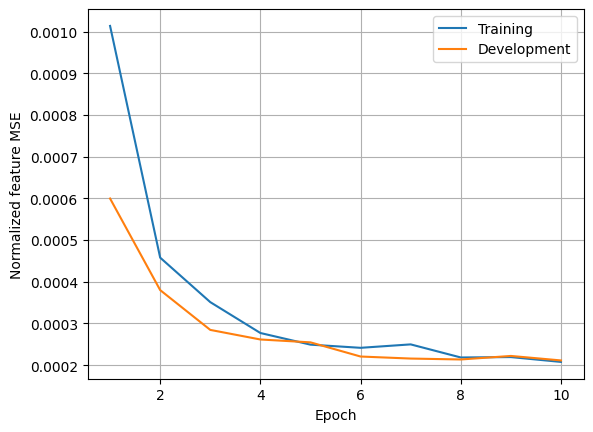

In [14]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_history) + 1)

plt.plot(epochs, train_history, label="Training")
plt.plot(epochs, dev_history, label="Development")

plt.xlabel("Epoch")
plt.ylabel("Normalized feature MSE")
plt.legend()
plt.grid(True)
plt.show()

---
## Stage 7 — Teacher–student anomaly heatmap

The frozen teacher and trained student produce a cosine-discrepancy map. This is a prototype detection score; testing across real defects is a later stage.

In [16]:
import math
import torch.nn.functional as F


@torch.no_grad()
def anomaly_score(image):
    """
    Return:
      1. A 224 x 224 teacher-student discrepancy map
      2. An image score: mean of the highest-scoring 1% of pixels
    """

    # Teacher preprocesses the image and extracts its features
    teacher_pixels, teacher_features = teacher.extract(
        image.convert("RGB")
    )

    # Student receives the same preprocessed image
    student_features = student_model(teacher_pixels)

    if teacher_features.shape != student_features.shape:
        raise ValueError("Teacher and student feature shapes do not match.")

    # Compare the 384-element feature vectors at each grid position.
    # Shape: [1, 14, 14]
    patch_map = 1 - F.cosine_similarity(
        teacher_features,
        student_features,
        dim=1
    )

    # Resize to the processed image size: [1, 1, 224, 224]
    image_map = F.interpolate(
        patch_map.unsqueeze(1),
        size=teacher_pixels.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    # Average the highest-scoring 1% of pixels
    flattened = image_map.flatten()
    k = max(1, math.ceil(0.01 * flattened.numel()))

    score = torch.topk(flattened, k).values.mean().item()

    return image_map[0, 0].cpu(), score

### Calibrate a normal-image threshold for each category

Thresholds are estimated only from held-out **normal development images**, never from real defective test images. Different categories can have different normal discrepancy scores.

In [17]:
import json

thresholds_path = checkpoint_dir / f'student_all_15_{run_id}_thresholds.json'
threshold_version = 'cosine_top1percent_normal95_v1'

if thresholds_path.is_file() and not FORCE_RETRAIN:
    saved_thresholds = json.loads(thresholds_path.read_text())
else:
    saved_thresholds = {}

if (saved_thresholds.get('run_id') == run_id
        and saved_thresholds.get('version') == threshold_version
        and set(saved_thresholds.get('thresholds', {})) == set(ALL_CATEGORIES)):
    category_thresholds = saved_thresholds['thresholds']
    print('Loaded existing normal-development thresholds from Drive.')
else:
    category_thresholds = {}
    for category in ALL_CATEGORIES:
        dev_scores = []
        for path in category_dev_paths[category]:
            with Image.open(path) as image:
                _, score = anomaly_score(image)
            dev_scores.append(score)
        category_thresholds[category] = torch.quantile(
            torch.tensor(dev_scores, dtype=torch.float32), 0.95
        ).item()
        print(f'{category:13s}: {len(dev_scores):3d} normal dev images | '
              f'threshold {category_thresholds[category]:.6f}')
    thresholds_path.write_text(json.dumps({
        'run_id': run_id,
        'version': threshold_version,
        'thresholds': category_thresholds,
    }, indent=2))
    print('Saved threshold estimates:', thresholds_path)

# Keep the existing bottle visualization compatible.
threshold = category_thresholds['bottle']
print('Bottle 95th-percentile normal-development threshold:', threshold)

Loaded existing normal-development thresholds from Drive.
Bottle 95th-percentile normal-development threshold: 0.14444123208522797


Image: 000.png
Anomaly score: 0.2199566662311554
Threshold: 0.14444123208522797
Prediction: REVIEW — possible defect


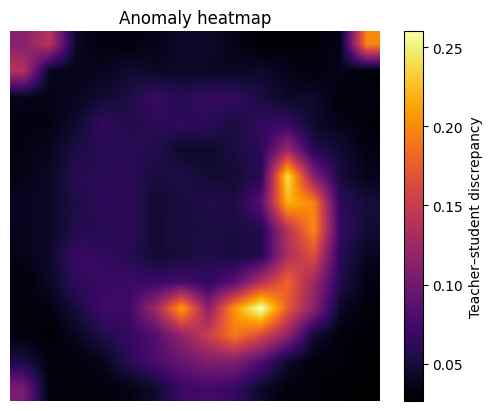

In [18]:
import matplotlib.pyplot as plt

with Image.open(defect_path) as image:
    heatmap, score = anomaly_score(image)

prediction = "REVIEW — possible defect" if score > threshold else "PASS"

print("Image:", defect_path.name)
print("Anomaly score:", score)
print("Threshold:", threshold)
print("Prediction:", prediction)

plt.imshow(heatmap, cmap="inferno")
plt.colorbar(label="Teacher–student discrepancy")
plt.title("Anomaly heatmap")
plt.axis("off")
plt.show()

Category: tile
Image: 013.png
Actual label: DEFECTIVE
Anomaly score: 0.42298
Threshold:     0.07849
Prediction: REVIEW


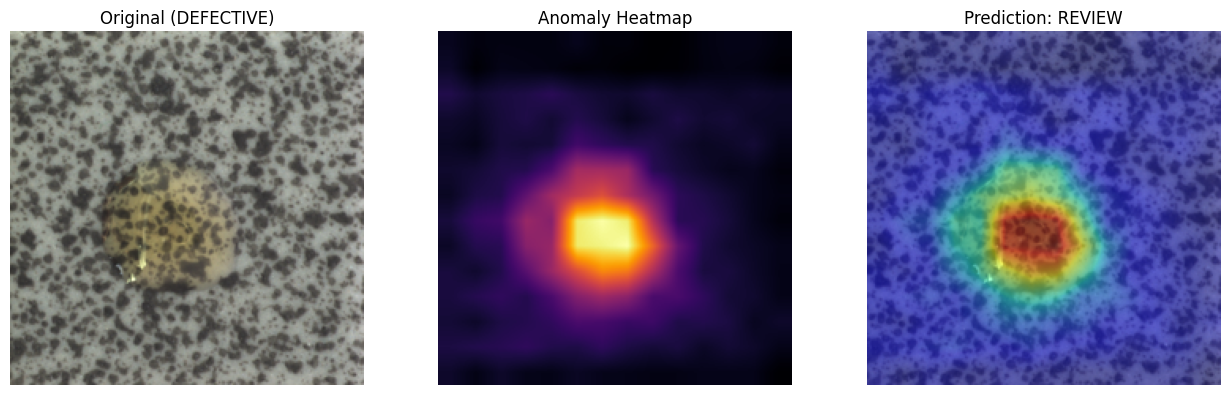

In [19]:

import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Set to "bottle", "cable", etc., or None for a random category.
CATEGORY = None

# Set to "good", "defect", or None for a random choice.
IMAGE_TYPE = None

# 1. Select a random category and test image
category = CATEGORY or random.choice(list(ALL_CATEGORIES))
test_dir = MVTEC_ROOT / category / "test"

good_images = image_files(test_dir / "good")
defect_images = [
    path
    for folder in test_dir.iterdir()
    if folder.is_dir() and folder.name != "good"
    for path in image_files(folder)
]

image_type = IMAGE_TYPE or random.choice(["good", "defect"])
image_path = random.choice(
    good_images if image_type == "good" else defect_images
)

# 2. Run our trained Teacher-Student model
with Image.open(image_path) as image:
    original = image.convert("RGB")
    heatmap, score = anomaly_score(original)

# 3. Compare the score with the category threshold
threshold = category_thresholds[category]
prediction = "REVIEW" if score > threshold else "PASS"
actual = "NORMAL" if image_type == "good" else "DEFECTIVE"

print("Category:", category)
print("Image:", image_path.name)
print("Actual label:", actual)
print(f"Anomaly score: {score:.5f}")
print(f"Threshold:     {threshold:.5f}")
print("Prediction:", prediction)

# 4. Display original image, heatmap and overlay
display_image = original.resize((224, 224))
heatmap_np = heatmap.numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(display_image)
axes[0].set_title(f"Original ({actual})")

axes[1].imshow(heatmap_np, cmap="inferno")
axes[1].set_title("Anomaly Heatmap")

axes[2].imshow(display_image)
axes[2].imshow(heatmap_np, cmap="jet", alpha=0.45)
axes[2].set_title(f"Prediction: {prediction}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Loaded: /content/anomaforge_ben/P3/synthetic.py
Categories: 15
Normal originals selected: 45
Generated samples: 90
NN3 input shape: (4, 224, 224)
Target mask shape: (1, 224, 224)


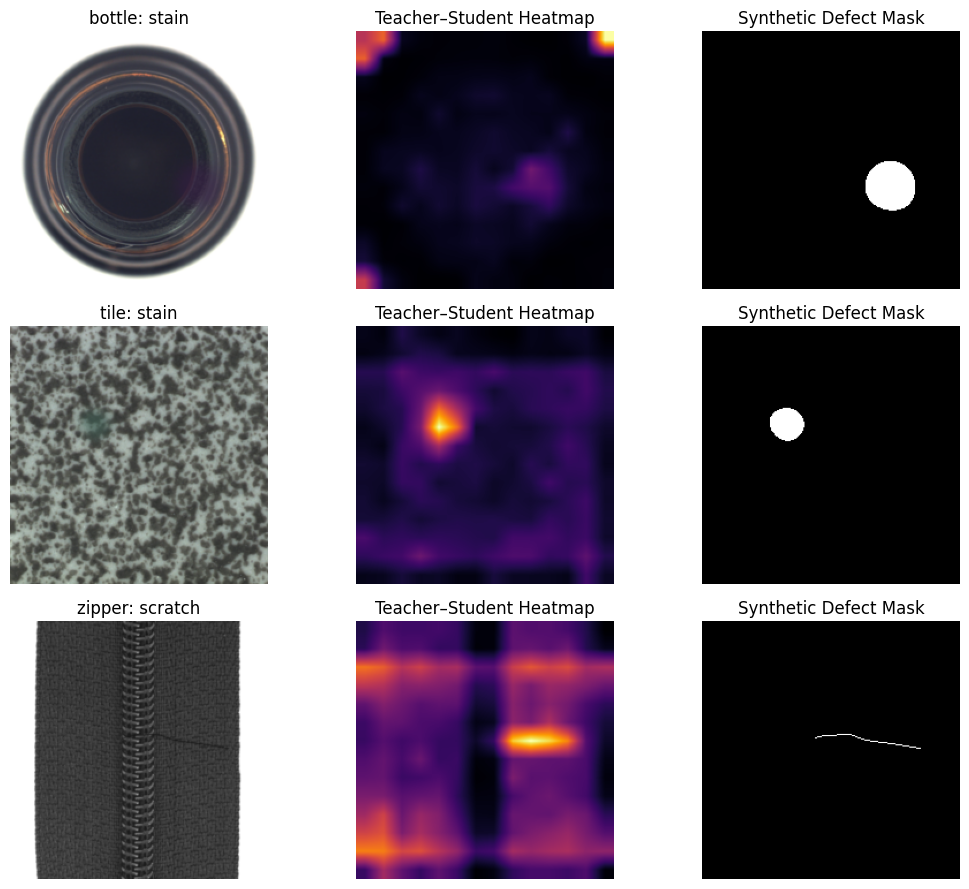

In [20]:

# Stage 8 — Ben's synthetic defect generator (all 15 categories)

import subprocess
import sys
import random
import importlib
import matplotlib.pyplot as plt
import torch
from pathlib import Path

# 1. Load Ben's code from GitHub
BEN_REPO = Path("/content/anomaforge_ben")
BEN_BRANCH = "feature/bschuller"
REPO_URL = "https://github.com/ANN-PROJECT-26/ANOMAFORGE.git"

if (BEN_REPO / ".git").is_dir():
    subprocess.run(
        ["git", "-C", str(BEN_REPO), "pull", "--ff-only",
         "origin", BEN_BRANCH],
        check=True
    )
elif not BEN_REPO.exists():
    subprocess.run(
        ["git", "clone", "--branch", BEN_BRANCH, "--single-branch",
         REPO_URL, str(BEN_REPO)],
        check=True
    )
else:
    raise RuntimeError("Ben's destination folder exists but is not a Git repository.")

BEN_DIR = BEN_REPO / "P3"
assert (BEN_DIR / "synthetic.py").is_file()

sys.path.insert(0, str(BEN_DIR))
importlib.invalidate_caches()
sys.modules.pop("synthetic", None)

from synthetic import SyntheticDefectDataset

print("Loaded:", BEN_DIR / "synthetic.py")


# 2. Use the saved, trained Student CNN
assert best_path.is_file(), "Student checkpoint not found. Run Cell 24."

state = torch.load(
    best_path, map_location=teacher.device, weights_only=True
)
student_model.load_state_dict(state["model_state_dict"])
student_model.eval()
teacher.model.eval()


# 3. Select normal training images from ALL categories
# Start small. Set to None to use ALL training images in every category.
MAX_IMAGES_PER_CATEGORY = 3
PER_IMAGE = 2

synthetic_paths = []
category_offsets = {}
category_counts = {}

for category in ALL_CATEGORIES:
    paths = list(category_train_paths[category])

    rng = random.Random(42)
    rng.shuffle(paths)

    if MAX_IMAGES_PER_CATEGORY is not None:
        paths = paths[:MAX_IMAGES_PER_CATEGORY]

    category_offsets[category] = len(synthetic_paths) * PER_IMAGE
    category_counts[category] = len(paths)
    synthetic_paths.extend(paths)

print("Categories:", len(category_counts))
print("Normal originals selected:", len(synthetic_paths))


# 4. Generate artificial defects, anomaly maps, and masks
# No cache for this first test, avoiding outdated stored maps.
synthetic_dataset = SyntheticDefectDataset(
    paths=synthetic_paths,
    teacher=teacher,
    student=student_model,
    per_image=PER_IMAGE,
    clean_fraction=0.2,
    seed=42,
    batch_size=8,
    cache_file=None,
    augment=False,
    map_scale=10.0
)

x, y = synthetic_dataset[0]

print("Generated samples:", len(synthetic_dataset))
print("NN3 input shape:", tuple(x.shape))
print("Target mask shape:", tuple(y.shape))


# 5. Visualize synthetic examples from different categories
show_categories = ["bottle", "tile", "zipper"]

fig, axes = plt.subplots(
    len(show_categories), 3, figsize=(11, 9)
)

for row, category in enumerate(show_categories):
    start = category_offsets[category]
    stop = start + category_counts[category] * PER_IMAGE

    # Prefer a defective example rather than a clean sample
    idx = next(
        (i for i in range(start, stop)
         if synthetic_dataset.kinds[i] != "clean"),
        start
    )

    image_input, mask = synthetic_dataset[idx]

    rgb = image_input[:3].permute(1, 2, 0).numpy()
    anomaly_map = image_input[3].numpy()
    defect_mask = mask[0].numpy()

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(
        f"{category}: {synthetic_dataset.kinds[idx]}"
    )

    axes[row, 1].imshow(anomaly_map, cmap="inferno")
    axes[row, 1].set_title("Teacher–Student Heatmap")

    axes[row, 2].imshow(defect_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Synthetic Defect Mask")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()
